# Zero-shot kidney cancer detection (Figure 6c-d)

Reads tables from `../data/` and writes figures to `../output/`. Source notebook is listed in `../../NOTEBOOK_PROVENANCE.tsv`.

In [1]:
from pathlib import Path
import sys

# Self-contained: works when run from this notebook's folder (nbconvert default),
# from the modality folder, or from the repo root.
nb_dir = Path.cwd()
if (nb_dir / "data").exists() and (nb_dir / "output").exists():
    MOD_DIR = nb_dir
elif (nb_dir.parent / "data").exists():
    MOD_DIR = nb_dir.parent
else:
    MOD_DIR = nb_dir
DATA = MOD_DIR / "data"
OUT = MOD_DIR / "output"
OUT.mkdir(exist_ok=True)

# Locate the shared style helper (src/leaf1figures) by walking up.
_p = nb_dir
while _p != _p.parent and not (_p / "src" / "leaf1figures").exists():
    _p = _p.parent
sys.path.insert(0, str(_p / "src"))

from leaf1figures.style import OKABE_ITO, savefig, set_paper_style
set_paper_style()
print("DATA:", DATA)
print("OUT :", OUT)


DATA: /home/hamedh/projects/fragmentomics/multi_modal_fragments/bert_window_embedding/draft/leaf-1-figures/cfdna/data
OUT : /home/hamedh/projects/fragmentomics/multi_modal_fragments/bert_window_embedding/draft/leaf-1-figures/cfdna/output


saved: /home/hamedh/projects/fragmentomics/multi_modal_fragments/bert_window_embedding/draft/leaf-1-figures/cfdna/output/kidney_roc.pdf
saved: /home/hamedh/projects/fragmentomics/multi_modal_fragments/bert_window_embedding/draft/leaf-1-figures/cfdna/output/kidney_roc.png
saved: /home/hamedh/projects/fragmentomics/multi_modal_fragments/bert_window_embedding/draft/leaf-1-figures/cfdna/output/kidney_roc.svg
saved: /home/hamedh/projects/fragmentomics/multi_modal_fragments/bert_window_embedding/draft/leaf-1-figures/cfdna/output/kidney_roc.tsv


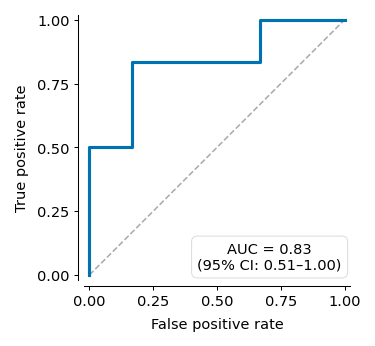

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
# Exact-source rcParams for this panel family.
plt.rcParams.update({
    'font.family': 'sans-serif',
    'font.sans-serif': ['Arial', 'DejaVu Sans', 'Helvetica'],
    'font.size': 7, 'axes.titlesize': 8, 'axes.labelsize': 7,
    'xtick.labelsize': 7, 'ytick.labelsize': 7, 'legend.fontsize': 6,
    'axes.linewidth': 0.5, 'xtick.major.width': 0.5, 'ytick.major.width': 0.5,
    'lines.linewidth': 1, 'figure.dpi': 150, 'savefig.dpi': 600,
    'savefig.bbox': 'tight', 'axes.spines.top': False, 'axes.spines.right': False,
})

from sklearn.metrics import roc_auc_score, roc_curve

df=pd.read_csv(DATA/'kidney_predictions_anonymized.csv'); y_true=df['label'].values; y_prob=df['prob_ensemble'].values
fpr_main,tpr_main,_=roc_curve(y_true,y_prob); auc_value=roc_auc_score(y_true,y_prob)
rng=np.random.default_rng(42); fpr_grid=np.linspace(0,1,100); tpr_boot=[]; auc_boot=[]
for _ in range(1000):
    idx=rng.choice(len(y_true), size=len(y_true), replace=True); yt,yp=y_true[idx],y_prob[idx]
    if len(np.unique(yt))<2: continue
    fpr_b,tpr_b,_=roc_curve(yt,yp); auc_boot.append(roc_auc_score(yt,yp)); tpr_boot.append(np.interp(fpr_grid,fpr_b,tpr_b))
tpr_boot=np.array(tpr_boot); auc_boot=np.array(auc_boot); auc_ci_low=np.percentile(auc_boot,2.5); auc_ci_high=np.percentile(auc_boot,97.5); tpr_lower=np.percentile(tpr_boot,2.5,axis=0); tpr_upper=np.percentile(tpr_boot,97.5,axis=0)
fig,ax=plt.subplots(figsize=(2.5,2.5)); ax.plot([0,1],[0,1],color='#AAAAAA',linestyle='--',linewidth=0.75,zorder=1); ax.plot(fpr_main,tpr_main,color=OKABE_ITO['blue'],linewidth=1.5,zorder=3); ax.text(0.97,0.03,f'AUC = {auc_value:.2f}\n(95% CI: {auc_ci_low:.2f}–{auc_ci_high:.2f})',transform=ax.transAxes,ha='right',va='bottom',fontsize=7,multialignment='center',bbox=dict(boxstyle='round,pad=0.4',facecolor='white',edgecolor='#DDDDDD',linewidth=0.5)); ax.set_xlabel('False positive rate'); ax.set_ylabel('True positive rate'); ax.set_xlim(-0.02,1.02); ax.set_ylim(-0.02,1.02); ax.set_xticks([0,0.25,0.5,0.75,1.0]); ax.set_yticks([0,0.25,0.5,0.75,1.0]); ax.set_aspect('equal'); ax.spines['left'].set_position(('outward',3)); ax.spines['bottom'].set_position(('outward',3)); ax.tick_params(axis='both',which='both',length=2,pad=2); plt.tight_layout(); savefig(fig, OUT, 'kidney_roc', data=(pd.DataFrame({'fpr':fpr_main,'tpr':tpr_main}).assign(auc=auc_value, auc_ci_low=auc_ci_low, auc_ci_high=auc_ci_high)))

saved: /home/hamedh/projects/fragmentomics/multi_modal_fragments/bert_window_embedding/draft/leaf-1-figures/cfdna/output/kidney_precision_recall.pdf
saved: /home/hamedh/projects/fragmentomics/multi_modal_fragments/bert_window_embedding/draft/leaf-1-figures/cfdna/output/kidney_precision_recall.png
saved: /home/hamedh/projects/fragmentomics/multi_modal_fragments/bert_window_embedding/draft/leaf-1-figures/cfdna/output/kidney_precision_recall.svg
saved: /home/hamedh/projects/fragmentomics/multi_modal_fragments/bert_window_embedding/draft/leaf-1-figures/cfdna/output/kidney_precision_recall.tsv


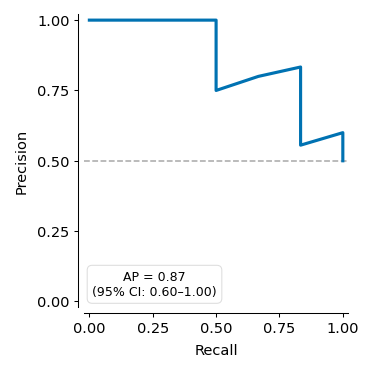

In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
# Exact-source rcParams for this panel family.
plt.rcParams.update({
    'font.family': 'sans-serif',
    'font.sans-serif': ['Arial', 'DejaVu Sans', 'Helvetica'],
    'font.size': 7, 'axes.titlesize': 8, 'axes.labelsize': 7,
    'xtick.labelsize': 7, 'ytick.labelsize': 7, 'legend.fontsize': 6,
    'axes.linewidth': 0.5, 'xtick.major.width': 0.5, 'ytick.major.width': 0.5,
    'lines.linewidth': 1, 'figure.dpi': 150, 'savefig.dpi': 600,
    'savefig.bbox': 'tight', 'axes.spines.top': False, 'axes.spines.right': False,
})

from sklearn.metrics import average_precision_score, precision_recall_curve

df=pd.read_csv(DATA/'kidney_predictions_anonymized.csv'); y_true=df['label'].values; y_prob=df['prob_ensemble'].values
precision,recall,_=precision_recall_curve(y_true,y_prob); ap_value=average_precision_score(y_true,y_prob); prevalence=y_true.mean(); rng=np.random.default_rng(42); ap_boot=[]
for _ in range(2000):
    idx=rng.choice(len(y_true), size=len(y_true), replace=True); yt,yp=y_true[idx],y_prob[idx]
    if len(np.unique(yt))<2: continue
    ap_boot.append(average_precision_score(yt,yp))
ap_ci_low,ap_ci_high=np.percentile(ap_boot,[2.5,97.5])
fig,ax=plt.subplots(figsize=(2.5,2.5)); ax.axhline(y=prevalence,color='#AAAAAA',linewidth=0.75,linestyle='--',zorder=1); ax.plot(recall,precision,color=OKABE_ITO['blue'],linewidth=1.5,zorder=3); ax.text(0.03,0.03,f'AP = {ap_value:.2f}\n(95% CI: {ap_ci_low:.2f}–{ap_ci_high:.2f})',transform=ax.transAxes,ha='left',va='bottom',fontsize=6,multialignment='center',bbox=dict(boxstyle='round,pad=0.4',facecolor='white',edgecolor='#DDDDDD',linewidth=0.5)); ax.set_xlabel('Recall'); ax.set_ylabel('Precision'); ax.set_xlim(-0.02,1.02); ax.set_ylim(-0.02,1.02); ax.set_xticks([0,0.25,0.5,0.75,1.0]); ax.set_yticks([0,0.25,0.5,0.75,1.0]); ax.spines['left'].set_position(('outward',3)); ax.spines['bottom'].set_position(('outward',3)); ax.tick_params(axis='both',which='both',length=2,pad=2); plt.tight_layout(); savefig(fig, OUT, 'kidney_precision_recall', data=(pd.DataFrame({'recall':recall,'precision':precision}).assign(ap=ap_value, ap_ci_low=ap_ci_low, ap_ci_high=ap_ci_high, prevalence=prevalence)))

saved: /home/hamedh/projects/fragmentomics/multi_modal_fragments/bert_window_embedding/draft/leaf-1-figures/cfdna/output/kidney_predictions_stripplot.pdf
saved: /home/hamedh/projects/fragmentomics/multi_modal_fragments/bert_window_embedding/draft/leaf-1-figures/cfdna/output/kidney_predictions_stripplot.png
saved: /home/hamedh/projects/fragmentomics/multi_modal_fragments/bert_window_embedding/draft/leaf-1-figures/cfdna/output/kidney_predictions_stripplot.svg
saved: /home/hamedh/projects/fragmentomics/multi_modal_fragments/bert_window_embedding/draft/leaf-1-figures/cfdna/output/kidney_predictions_stripplot.tsv


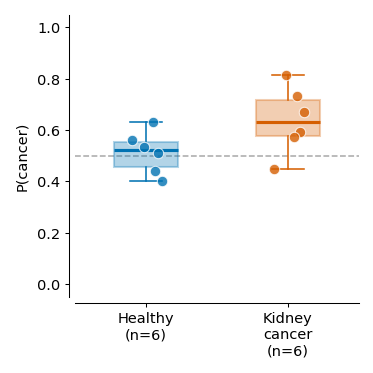

In [4]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
# Exact-source rcParams for this panel family.
plt.rcParams.update({
    'font.family': 'sans-serif',
    'font.sans-serif': ['Arial', 'DejaVu Sans', 'Helvetica'],
    'font.size': 7, 'axes.titlesize': 8, 'axes.labelsize': 7,
    'xtick.labelsize': 7, 'ytick.labelsize': 7, 'legend.fontsize': 6,
    'axes.linewidth': 0.5, 'xtick.major.width': 0.5, 'ytick.major.width': 0.5,
    'lines.linewidth': 1, 'figure.dpi': 150, 'savefig.dpi': 600,
    'savefig.bbox': 'tight', 'axes.spines.top': False, 'axes.spines.right': False,
})


df=pd.read_csv(DATA/'kidney_predictions_anonymized.csv'); fig,ax=plt.subplots(figsize=(2.5,2.5)); groups=['Healthy','Kidney_cancer']; colors=[OKABE_ITO['blue'],OKABE_ITO['orange']]
for i,(group,color) in enumerate(zip(groups,colors)):
    probs=df.loc[df['true_group']==group,'prob_ensemble'].values
    bp=ax.boxplot([probs],positions=[i],widths=0.45,patch_artist=True,showfliers=False)
    bp['boxes'][0].set_facecolor(color); bp['boxes'][0].set_alpha(0.3); bp['boxes'][0].set_edgecolor(color); bp['boxes'][0].set_linewidth(1); bp['medians'][0].set_color(color); bp['medians'][0].set_linewidth(1.5)
    for element in ['whiskers','caps']:
        for line in bp[element]: line.set_color(color); line.set_linewidth(0.75)
    jitter=np.random.default_rng(42).uniform(-0.12,0.12,len(probs)); ax.scatter(np.full_like(probs,i)+jitter, probs, c=color, s=25, alpha=0.8, edgecolors='white', linewidth=0.5, zorder=3)
ax.axhline(y=0.5,color='#AAAAAA',linewidth=0.75,linestyle='--',zorder=1); ax.set_xticks([0,1]); ax.set_xticklabels(['Healthy\n(n=6)','Kidney\ncancer\n(n=6)'],fontsize=6); ax.set_ylabel('P(cancer)'); ax.set_ylim(-0.05,1.05); ax.spines['left'].set_position(('outward',3)); ax.spines['bottom'].set_position(('outward',3)); ax.tick_params(axis='both',which='both',length=2,pad=2); plt.tight_layout(); savefig(fig, OUT, 'kidney_predictions_stripplot', data=(df.loc[df['true_group'].isin(groups), ['true_group','prob_ensemble']]))